In [18]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

In [19]:
PROJECT_ROOT = Path("..")

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

print("Reports:", REPORTS_DIR)
print("Figures:", FIGURES_DIR)

Reports: ../reports
Figures: ../reports/figures


In [20]:
with open(REPORTS_DIR / "final_results.json", "r") as file:
    final_results = json.load(file)

print(json.dumps(final_results, indent=4))

{
    "cardiovascular": {
        "models": [
            {
                "model": "Logistic Regression",
                "accuracy": 0.7312600850814142,
                "precision": 0.760400747155714,
                "recall": 0.6652800475412272,
                "f1": 0.7096671949286846,
                "roc_auc": 0.7938238781503816
            },
            {
                "model": "Random Forest",
                "accuracy": 0.7124101510928561,
                "precision": 0.7103293413173652,
                "recall": 0.7049472589511216,
                "f1": 0.7076280665125643,
                "roc_auc": 0.7668691606656349
            },
            {
                "model": "HistGradientBoosting",
                "accuracy": 0.7366876925333724,
                "precision": 0.7534290785864127,
                "recall": 0.6936562175011143,
                "f1": 0.7223081683168316,
                "roc_auc": 0.8037965144396555
            }
        ]
    },
    "ptbxl_cnn": {
 

In [21]:
cardio_results = pd.read_csv(REPORTS_DIR / "tabular_model_test_comparison.csv")

print(cardio_results.to_string(index=False))

               model  accuracy  precision   recall       f1  roc_auc   pr_auc
 Logistic Regression  0.731260   0.760401 0.665280 0.709667 0.793824 0.773638
       Random Forest  0.712410   0.710329 0.704947 0.707628 0.766869 0.744146
HistGradientBoosting  0.736688   0.753429 0.693656 0.722308 0.803797 0.784888


In [22]:
ptbxl_results = pd.read_csv(REPORTS_DIR / "ptbxl_cnn_final_metrics.csv")

print(ptbxl_results.to_string(index=False))

                 metric  value
          ROC-AUC Macro 0.9015
          ROC-AUC Micro 0.9185
Average Precision Macro 0.7618
Average Precision Micro 0.8239
               F1 Macro 0.7036
               F1 Micro 0.7489


In [23]:
cardio_summary = cardio_results[
    ["model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
].copy()

cardio_summary

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.731260,0.760401,0.665280,0.709667,0.793824,0.773638
1,Random Forest,0.712410,0.710329,0.704947,0.707628,0.766869,0.744146
2,HistGradientBoosting,0.736688,0.753429,0.693656,0.722308,0.803797,0.784888


In [24]:
ptbxl_summary = ptbxl_results.copy()

ptbxl_summary

,metric,value
0,ROC-AUC Macro,0.9015
1,ROC-AUC Micro,0.9185
2,Average Precision Macro,0.7618
3,Average Precision Micro,0.8239
4,F1 Macro,0.7036
5,F1 Micro,0.7489


In [25]:
methodology = pd.DataFrame(
    {
        "Dataset": ["Cardiovascular Disease", "PTB-XL"],
        "Input": ["Patient demographic and clinical features", "12-lead ECG signals"],
        "Task": ["Binary classification", "Multi-label classification"],
        "Target": ["Cardiovascular disease", "ECG diagnostic classes"],
        "Models": [
            "Logistic Regression, Random Forest, HistGradientBoosting",
            "1D CNN",
        ],
    }
)

methodology

,Dataset,Input,Task,Target,Models
0,Cardiovascular Disease,Patient demographic and clinical features,Binary classification,Cardiovascular disease,"Logistic Regression, Random Forest, HistGradie..."
1,PTB-XL,12-lead ECG signals,Multi-label classification,ECG diagnostic classes,1D CNN


In [26]:
dataset_summary = pd.DataFrame(
    {
        "Dataset": ["Cardiovascular Disease", "PTB-XL"],
        "Samples": [68205, 21799],
        "Input Type": ["Tabular", "12-lead ECG"],
        "Prediction Type": ["Binary", "Multi-label"],
    }
)

dataset_summary

,Dataset,Samples,Input Type,Prediction Type
0,Cardiovascular Disease,68205,Tabular,Binary
1,PTB-XL,21799,12-lead ECG,Multi-label


In [27]:
cardio_report = cardio_results[["model", "accuracy", "f1", "roc_auc", "pr_auc"]].copy()

cardio_report.columns = ["Model", "Accuracy", "F1", "ROC-AUC", "PR-AUC"]

cardio_report

,Model,Accuracy,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.731260,0.709667,0.793824,0.773638
1,Random Forest,0.712410,0.707628,0.766869,0.744146
2,HistGradientBoosting,0.736688,0.722308,0.803797,0.784888


In [28]:
ptbxl_key_metrics = ptbxl_results[
    ptbxl_results["metric"].isin(
        [
            "ROC-AUC Macro",
            "ROC-AUC Micro",
            "Average Precision Macro",
            "Average Precision Micro",
            "F1 Macro",
            "F1 Micro",
        ]
    )
].copy()

ptbxl_key_metrics

,metric,value
0,ROC-AUC Macro,0.9015
1,ROC-AUC Micro,0.9185
2,Average Precision Macro,0.7618
3,Average Precision Micro,0.8239
4,F1 Macro,0.7036
5,F1 Micro,0.7489


In [29]:
class_metrics = pd.read_csv(REPORTS_DIR / "ptbxl_cnn_class_metrics.csv")

print(class_metrics.to_string(index=False))

class  threshold  test_f1
 NORM       0.47   0.8444
   MI       0.21   0.7259
 STTC       0.42   0.7517
   CD       0.45   0.7330
  HYP       0.23   0.4632


In [30]:
class_metrics_report = class_metrics.copy()

class_metrics_report.columns = [
    "Diagnostic Class",
    "Classification Threshold",
    "Test F1",
]

class_metrics_report

,Diagnostic Class,Classification Threshold,Test F1
0,NORM,0.47,0.8444
1,MI,0.21,0.7259
2,STTC,0.42,0.7517
3,CD,0.45,0.7330
4,HYP,0.23,0.4632


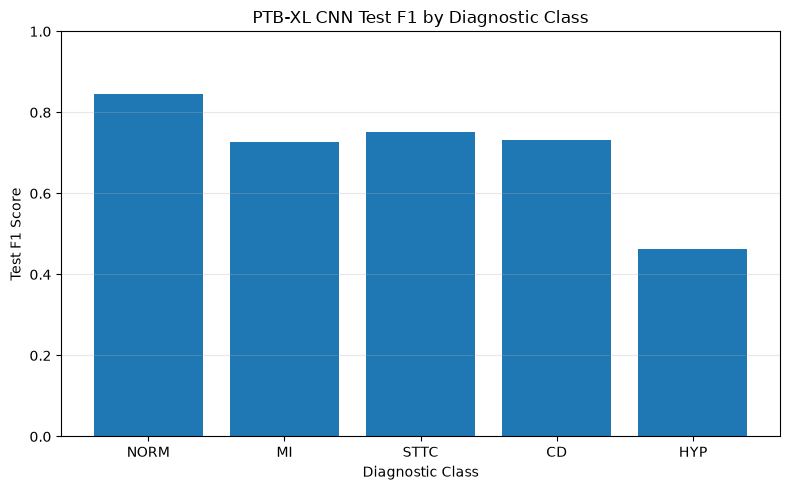

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(class_metrics["class"], class_metrics["test_f1"])

plt.xlabel("Diagnostic Class")

plt.ylabel("Test F1 Score")

plt.title("PTB-XL CNN Test F1 by Diagnostic Class")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(FIGURES_DIR / "ptbxl_class_f1.png", dpi=300, bbox_inches="tight")

plt.show()

In [32]:
interpretation = pd.read_csv(
    REPORTS_DIR / "interpretation" / "ptbxl_cnn_interpretation_summary.csv"
)

interpretation

,class,top_lead,top_lead_importance
0,NORM,aVR,0.151545
1,MI,V2,0.067743
2,STTC,aVR,0.187014
3,CD,V1,0.100835
4,HYP,V1,0.178855


In [33]:
print("""
FINAL PROJECT SUMMARY
=====================

1. The project uses two complementary cardiovascular datasets.

2. The Cardiovascular Disease dataset is treated as a binary
   classification problem using demographic, lifestyle, and
   clinical variables.

3. Multiple tabular machine-learning models were evaluated:
   Logistic Regression, Random Forest, and
   HistGradientBoosting.

4. The PTB-XL dataset is treated as a multi-label ECG
   classification problem.

5. A 1D CNN is used to learn diagnostic patterns directly
   from 12-lead ECG signals.

6. Model evaluation uses appropriate classification metrics
   rather than accuracy alone.

7. The project also includes model interpretation:
   tabular coefficient analysis and ECG lead-importance
   analysis.

8. The two datasets address different prediction tasks and
   should therefore be evaluated separately rather than
   treating their metrics as directly interchangeable.
""")


FINAL PROJECT SUMMARY

1. The project uses two complementary cardiovascular datasets.

2. The Cardiovascular Disease dataset is treated as a binary
   classification problem using demographic, lifestyle, and
   clinical variables.

3. Multiple tabular machine-learning models were evaluated:
   Logistic Regression, Random Forest, and
   HistGradientBoosting.

4. The PTB-XL dataset is treated as a multi-label ECG
   classification problem.

5. A 1D CNN is used to learn diagnostic patterns directly
   from 12-lead ECG signals.

6. Model evaluation uses appropriate classification metrics
   rather than accuracy alone.

7. The project also includes model interpretation:
   tabular coefficient analysis and ECG lead-importance
   analysis.

8. The two datasets address different prediction tasks and
   should therefore be evaluated separately rather than
   treating their metrics as directly interchangeable.



In [34]:
required_files = [
    "tabular_model_test_comparison.csv",
    "tabular_final_results.csv",
    "ptbxl_cnn_final_metrics.csv",
    "ptbxl_cnn_class_metrics.csv",
    "ptbxl_threshold_comparison.csv",
    "final_results.json",
    "final_report_table.csv",
]

print("Required report files:")
print()

for filename in required_files:

    path = REPORTS_DIR / filename

    status = "OK" if path.exists() else "MISSING"

    print(f"{status:8} {filename}")

Required report files:

OK       tabular_model_test_comparison.csv
OK       tabular_final_results.csv
OK       ptbxl_cnn_final_metrics.csv
OK       ptbxl_cnn_class_metrics.csv
OK       ptbxl_threshold_comparison.csv
OK       final_results.json
OK       final_report_table.csv


In [35]:
print("Final figures:")
print()

for figure in sorted(FIGURES_DIR.glob("*.png")):
    print("OK ", figure.name)

Final figures:

OK  cardiovascular_f1.png
OK  cardiovascular_model_comparison.png
OK  cardiovascular_roc_auc.png
OK  ptbxl_class_f1.png
OK  ptbxl_cnn_overall_metrics.png
OK  ptbxl_lead_importance.png
OK  ptbxl_threshold_comparison.png
OK  ptbxl_top_leads_by_class.png
